# Robotics Club Induction: Neural Networks
## Week 2 Assignment: Linear Regression & Gradient Descent from Scratch

Welcome to Week 2 of the Robotics Club Induction!

In this assignment, you will build a multivariate linear regression model entirely from scratch using `numpy`. No `sklearn` magic allowed this week! You will be working with the California Housing Dataset to predict median house values.

### 📚 Resources for this Week

*   **Linear Regression:** [StatQuest: Fitting a Line to Data](https://www.youtube.com/watch?v=PaFPbb66DxQ)
*   **Gradient Descent (Step-by-step):** [StatQuest: Gradient Descent, Step-by-Step](https://www.youtube.com/watch?v=sDv4f4s2SB8)
*   **Numpy Cheat Sheet:** [Numpy Documentation](https://numpy.org/doc/stable/user/quickstart.html)
*   **Pandas Basics (Doc):** [10 minutes to pandas](https://pandas.pydata.org/docs/user_guide/10min.html)

## Instructions

- Make a copy of this Colab notebook (else any changes you make wont be saved)
- Feel free to add more code blocks in between questions if you feel you need it
- For each code comment some lines explaining what approach did you use to solve the question.
- We expect that you will not use llms and try to solve this assignment on your own with the help of the resources given to you

Name:- Agrim Agarwal

ID:- 2026A7PS0407G

### Section 1: Data Preprocessing
Real-world data is messy. Before feeding it to a model, we must clean and format it.

In [4]:
#mount drive to access dataset
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the Data
df=  pd.read_csv("housing - housing.csv")

# 2. Clean the Data: Drop the 'ocean_proximity' column
df=df.drop(columns=["ocean_proximity"])
# 3. Handle Missing Values: Fill NaNs with the mean of their respective columns
df=df.fillna(value=df.mean())
# 4. Convert to Numpy: Separate features (x) and target (y), reshape y to 2D
# x = ...
x=df.drop(columns=["median_house_value"]).to_numpy()

# y = ...
#2d matrix with one column
y=df["median_house_value"].to_numpy().reshape(-1, 1)

# 5. Feature Scaling: Normalise your features x (subtract mean, divide by std)
# x = ...
# did axis =0 cuz we wanted column wise operations, as our matrix x is like each column is each proeprty
x = (x-x.mean(axis=0))/x.std(axis=0)
y.std()

np.float64(115392.82040412253)

### Section 2: Mathematical Foundations
Now we set up the architecture of our single-neuron model.

In [6]:
def initialize_parameters(num_features):
    """
    Initializes the weights as a numpy array of zeros and bias as 0.
    """
    # weights = ...
    weights = np.zeros([num_features,1])
    # bias = ...
    bias = 0.0
    #0.0 and not a vector, as np will automatically consider it as a vector (of appropraite size)
    #while doing vector addition to get Y vector
    return weights, bias

def predict(x, weights, bias):
    """
    Calculates the forward pass prediction using the linear regression formula.
    """
    # pred = ...
    pred = x@weights+bias
    # at the rate was for matrix multiplication
    return pred

def cost_func(y, pred):
    """
    Calculates the Mean Squared Error (MSE) between actual y and predicted values.
    """
    #minimizing mse would be the same as minimising sum of squared residuals (i.e sum of (predicted value - observed value))
    # to find sum(pred - y)
#we have to square the difference of each element of pred matrix  and each element of y and get the resultant amtrix say K
#then sum the elements of K
    # mse = ...
    mse = np.sum((pred-y)**2)/y.shape[0]
    return mse

initialize_parameters(8)

(array([[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]]),
 0.0)

### Section 3: The Learning Algorithm
This is where the magic happens. We will update our weights and bias to minimize the cost function.

In [7]:
def gradient_descent(x, y, weights, bias, learning_rate, iterations):
    """
    Updates weights and bias iteratively to minimize the cost function.
    """
    m = len(y) # Number of training examples
    for i in range(iterations):
        # 1. Calculate predictions
        # pred = ...
        pred = predict(x, weights, bias)
        mse = cost_func(y, pred)

                # 2. Calculate gradients (dw and db)

        #mse is basically (1/n)summation of (pred-y)^2 i.e (1/m)summation of (wx+b-y)^2
        #it's partial derivates w.r.t w gives using chain rule, 2/m *summation((wx+b-y)*x)
        #our dw is basically the matrix, containing the partial derivative of our mse with each weight
        #dw will be like a column matrix = [partial derivative w.r.t w1, partial derivative w.r.t w2, ..... partial derivative w.r.t w8]
        #dw1 is dw₁ = (2/m) · Σ (predᵢ − yᵢ) · xᵢ₁  where xi1 is the ith house's first feature
        #our (pred-y) size is (m,1)  where m is no. of houses, n is no. of features
        # xT will be of size (n,m)
        #and multiplying (pred-y) with xT would be a matrix of (n,1) with each row being the summation of (pred-y)*x where x is that specific feature, and this summation is over all the houses


        #partial derivative w.r.t b is 2/m * summation(wx+b-y)

        dw = (2/m)*x.T@(pred-y)
        # dw = ... (Hint: use dot product of x.T and the error)
        # db = ... (Hint: sum the errors)
        db  = (2/m)*np.sum(pred-y)
        # 3. Update parameters
        # weights = ...
#the main idea of gradient descent is that, if the slope is high in maginitude, we take bigger steps to go down
#now, as we move towards the right  (dw is negative in this case), the slope in magnitude keeps decrasing
#as it keeps decreasing, we take baby steps
#and when slope is almost 0, we have stopped taking steps, i.e weights matrix is almost constant

        weights=weights-dw*learning_rate
        # bias = ...
        bias = bias-db*learning_rate
        # Print cost every 1000 iterations for debugging
        if i % 1000 == 0:
          print(f"Iteration {i}: cost = {mse}")
          pass

    return weights, bias

### Section 4: Training and Evaluation
Let's put it all together and see how our model performs.

In [19]:
# 1. Initialize parameters based on your feature shape
# num_features = ...
# weights, bias = ...
num_features = x.shape[1]
weights,bias = initialize_parameters(num_features)
# 2. Train the model
learning_rate = 0.00001
iterations = 100000
weights, bias = gradient_descent(x,y, weights, bias, learning_rate, iterations)

# 3. Final Evaluation
# final_pred = ...
final_pred = predict(x, weights, bias)
# final_cost = ...
final_cost = cost_func(y, final_pred)
# 4. Print MSE for final model
print(f"The final cost is {final_cost}")

Iteration 0: cost = 56104831989.87253
Iteration 1000: cost = 54149136720.72357
Iteration 2000: cost = 52270710951.2874
Iteration 3000: cost = 50466401044.48192
Iteration 4000: cost = 48733194693.31122
Iteration 5000: cost = 47068212876.32497
Iteration 6000: cost = 45468702486.09343
Iteration 7000: cost = 43932029552.926216
Iteration 8000: cost = 42455672996.51532
Iteration 9000: cost = 41037218847.16083
Iteration 10000: cost = 39674354885.946014
Iteration 11000: cost = 38364865659.85361
Iteration 12000: cost = 37106627833.51253
Iteration 13000: cost = 35897605844.1626
Iteration 14000: cost = 34735847830.643776
Iteration 15000: cost = 33619481810.849087
Iteration 16000: cost = 32546712085.213547
Iteration 17000: cost = 31515815846.511772
Iteration 18000: cost = 30525139978.572548
Iteration 19000: cost = 29573098028.534386
Iteration 20000: cost = 28658167339.013355
Iteration 21000: cost = 27778886328.06584
Iteration 22000: cost = 26933851906.142807
Iteration 23000: cost = 26121717020.372

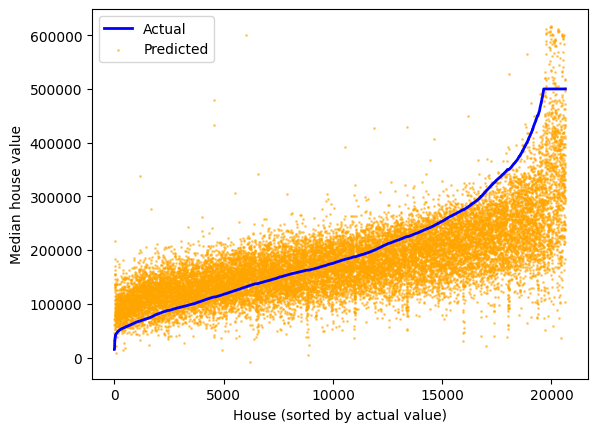

In [20]:
# Visualization
# 1. Flatten y and final_pred arrays to 1D
# y_flat = ...
# pred_flat = ...
y_flat = y.flatten()
pred_flat = final_pred.flatten()
# 2. Sort arrays by actual y values for a smooth line plot
idx = np.argsort(y_flat)
y_sorted = y_flat[idx]
pred_sorted = pred_flat[idx]
# 3. Plot Actual vs Predicted
plt.plot(y_sorted, label="Actual", color="blue", linewidth=2)
plt.scatter(range(len(pred_sorted)), pred_sorted, s=1, color="orange", alpha=0.5, label="Predicted")
plt.xlabel("House (sorted by actual value)")
plt.ylabel("Median house value")
plt.legend()
plt.show()